In [1]:
print("It is working")

It is working


In [3]:

import pandas as pd
import numpy as np
import duckdb
import matplotlib.pyplot as plt

print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("DuckDB version:", duckdb.__version__)


All libraries imported successfully!
Pandas version: 3.1.1
NumPy version: 2.5.4
DuckDB version: 2.0.0


In [3]:

from pathlib import Path

data_dir = Path("E:/Cloud_cost_capstone/data/raw/fastStorage/2013-8")

csv_files = sorted(data_dir.glob("*.csv"))

print("Folder exists:", data_dir.is_dir())
print("Number of CSV files:", len(csv_files))


Folder exists: True
Number of CSV files: 1250


In [8]:
csv_files = sorted(data_dir.rglob("*.csv"))

print("CSV files found:", len(csv_files))

for file in csv_files[:5]:
    print(file.name)

CSV files found: 1250
1.csv
10.csv
100.csv
1000.csv
1001.csv


In [4]:

import pandas as pd

sample_file = csv_files[0]

df = pd.read_csv(sample_file, sep=";")

print("File:", sample_file.name)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())


File: 1.csv
Number of rows: 8634
Number of columns: 11


,Timestamp [ms],\tCPU cores,\tCPU capacity provisioned [MHZ],\tCPU usage [MHZ],\tCPU usage [%],\tMemory capacity provisioned [KB],\tMemory usage [KB],\tDisk read throughput [KB/s],\tDisk write throughput [KB/s],\tNetwork received throughput [KB/s],\tNetwork transmitted throughput [KB/s]
0,1376314846,4,11703.99824,10912.027692,93.233333,67108864.0,6.129274e+06,0.133333,15981.600000,0.000000,2.133333
1,1376315146,4,11703.99824,10890.570362,93.050000,67108864.0,6.755624e+06,1.333333,19137.333333,0.000000,2.600000
2,1376315446,4,11703.99824,10434.114431,89.150000,67108864.0,8.947846e+06,2.533333,19974.933333,535.666667,23.933333
3,1376315746,4,11703.99824,10539.450415,90.050000,67108864.0,1.879048e+07,5.466667,8791.800000,349.666667,5.466667
4,1376316046,4,11703.99824,10951.041020,93.566667,67108864.0,9.305761e+06,5.400000,15679.533333,0.000000,2.066667


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8634 entries, 0 to 8633
Data columns (total 11 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   Timestamp [ms]                          8634 non-null   int64  
 1   	CPU cores                              8634 non-null   int64  
 2   	CPU capacity provisioned [MHZ]         8634 non-null   float64
 3   	CPU usage [MHZ]                        8634 non-null   float64
 4   	CPU usage [%]                          8634 non-null   float64
 5   	Memory capacity provisioned [KB]       8634 non-null   float64
 6   	Memory usage [KB]                      8634 non-null   float64
 7   	Disk read throughput [KB/s]            8634 non-null   float64
 8   	Disk write throughput [KB/s]           8634 non-null   float64
 9   	Network received throughput [KB/s]     8634 non-null   float64
 10  	Network transmitted throughput [KB/s]  8634 non-null   float64
dtypes:

In [ ]:
df.shape    #shows the rows and coloumns

(8634, 11)

In [7]:
df.describe

<bound method DataFrame.describe of       Timestamp [ms]  \tCPU cores  \tCPU capacity provisioned [MHZ]  \
0         1376314846            4                       11703.99824   
1         1376315146            4                       11703.99824   
2         1376315446            4                       11703.99824   
3         1376315746            4                       11703.99824   
4         1376316046            4                       11703.99824   
...              ...          ...                               ...   
8629      1378905598            4                       11703.99824   
8630      1378905898            4                       11703.99824   
8631      1378906198            4                       11703.99824   
8632      1378906498            4                       11703.99824   
8633      1378906798            4                       11703.99824   

      \tCPU usage [MHZ]  \tCPU usage [%]  \tMemory capacity provisioned [KB]  \
0          10912.027692        

In [ ]:
#Finiding the timestamp whether it is in ms or s
timestamp = 1376314846

print(pd.to_datetime(timestamp, unit="s", utc=True))
print(pd.to_datetime(timestamp, unit="ms", utc=True))

2013-08-12 13:40:46+00:00
1970-01-16 22:18:34.846000+00:00


In [12]:
print("First five timestamps:")
print(df.iloc[:5, 0].to_list())

print("\nLast five timestamps:")
print(df.iloc[-5:, 0].to_list())

First five timestamps:
[1376314846, 1376315146, 1376315446, 1376315746, 1376316046]

Last five timestamps:
[1378905598, 1378905898, 1378906198, 1378906498, 1378906798]


In [13]:

# Convert the raw Unix timestamps into readable UTC dates

timestamps = pd.to_datetime(df.iloc[:, 0], unit="s", utc=True)

print("First five dates:")
print(timestamps.head())

print("\nLast five dates:")
print(timestamps.tail())


First five dates:
0   2013-08-12 13:40:46+00:00
1   2013-08-12 13:45:46+00:00
2   2013-08-12 13:50:46+00:00
3   2013-08-12 13:55:46+00:00
4   2013-08-12 14:00:46+00:00
Name: Timestamp [ms], dtype: datetime64[us, UTC]

Last five dates:
8629   2013-09-11 13:19:58+00:00
8630   2013-09-11 13:24:58+00:00
8631   2013-09-11 13:29:58+00:00
8632   2013-09-11 13:34:58+00:00
8633   2013-09-11 13:39:58+00:00
Name: Timestamp [ms], dtype: datetime64[us, UTC]


In [14]:

# Calculate intervals between consecutive timestamps
intervals = df.iloc[:, 0].diff().dropna()

print("Most common intervals (seconds):")
print(intervals.value_counts().head(10))

print("\nMinimum interval:", intervals.min())
print("Maximum interval:", intervals.max())


Most common intervals (seconds):
Timestamp [ms]
300.0    8298
301.0     284
299.0      44
600.0       3
303.0       1
310.0       1
599.0       1
900.0       1
Name: count, dtype: int64

Minimum interval: 299.0
Maximum interval: 900.0


In [15]:

print("Missing values per column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())


Missing values per column:
Timestamp [ms]                             0
\tCPU cores                                0
\tCPU capacity provisioned [MHZ]           0
\tCPU usage [MHZ]                          0
\tCPU usage [%]                            0
\tMemory capacity provisioned [KB]         0
\tMemory usage [KB]                        0
\tDisk read throughput [KB/s]              0
\tDisk write throughput [KB/s]             0
\tNetwork received throughput [KB/s]       0
\tNetwork transmitted throughput [KB/s]    0
dtype: int64

Total missing values:
0


In [14]:

print("Duplicate rows:", df.duplicated().sum())

print("Duplicate timestamps:",
      df["Timestamp [ms]"].duplicated().sum())

Duplicate rows: 0
Duplicate timestamps: 0


In [17]:

display(df.describe())


,Timestamp [ms],\tCPU cores,\tCPU capacity provisioned [MHZ],\tCPU usage [MHZ],\tCPU usage [%],\tMemory capacity provisioned [KB],\tMemory usage [KB],\tDisk read throughput [KB/s],\tDisk write throughput [KB/s],\tNetwork received throughput [KB/s],\tNetwork transmitted throughput [KB/s]
count,8.634000e+03,8634.0,8.634000e+03,8634.000000,8634.000000,8634.0,8.634000e+03,8634.000000,8634.000000,8634.000000,8634.000000
mean,1.377611e+09,4.0,1.170400e+04,470.808807,4.022632,67108864.0,3.968319e+05,9.068713,412.470582,12.548241,2.982650
std,7.485558e+05,0.0,1.819095e-12,1978.426530,16.903852,0.0,2.072866e+06,149.350246,2439.051168,139.738027,32.803417
min,1.376315e+09,4.0,1.170400e+04,58.519991,0.500000,67108864.0,0.000000e+00,0.000000,0.285714,0.000000,0.928571
25%,1.376962e+09,4.0,1.170400e+04,66.322657,0.566667,67108864.0,0.000000e+00,0.000000,0.600000,0.000000,1.000000
50%,1.377611e+09,4.0,1.170400e+04,72.174656,0.616667,67108864.0,0.000000e+00,0.000000,0.666667,0.000000,1.000000
75%,1.378259e+09,4.0,1.170400e+04,78.026655,0.666667,67108864.0,0.000000e+00,0.000000,1.000000,0.000000,1.000000
max,1.378907e+09,4.0,1.170400e+04,11454.312944,97.866667,67108864.0,3.632826e+07,8544.733333,56630.600000,3563.800000,1022.666667


In [18]:

# Remove leading/trailing whitespace from column names
df.columns = df.columns.str.strip()

print(df.columns.tolist())


['Timestamp [ms]', 'CPU cores', 'CPU capacity provisioned [MHZ]', 'CPU usage [MHZ]', 'CPU usage [%]', 'Memory capacity provisioned [KB]', 'Memory usage [KB]', 'Disk read throughput [KB/s]', 'Disk write throughput [KB/s]', 'Network received throughput [KB/s]', 'Network transmitted throughput [KB/s]']


In [18]:
print(df.columns.tolist())

['Timestamp [ms]', '\tCPU cores', '\tCPU capacity provisioned [MHZ]', '\tCPU usage [MHZ]', '\tCPU usage [%]', '\tMemory capacity provisioned [KB]', '\tMemory usage [KB]', '\tDisk read throughput [KB/s]', '\tDisk write throughput [KB/s]', '\tNetwork received throughput [KB/s]', '\tNetwork transmitted throughput [KB/s]']


In [20]:
df.columns = df.columns.str.strip()

In [21]:

cpu_mhz = df["CPU usage [MHZ]"]
cpu_capacity = df["CPU capacity provisioned [MHZ]"]
cpu_percent = df["CPU usage [%]"]

calculated_cpu_percent = (cpu_mhz / cpu_capacity) * 100

comparison = pd.DataFrame({
    "Recorded CPU %": cpu_percent,
    "Calculated CPU %": calculated_cpu_percent,
    "Difference": cpu_percent - calculated_cpu_percent
})

display(comparison.head(10))


,Recorded CPU %,Calculated CPU %,Difference
0,93.233333,93.233333,0.000000e+00
1,93.050000,93.050000,0.000000e+00
2,89.150000,89.150000,1.421085e-14
3,90.050000,90.050000,-1.421085e-14
4,93.566667,93.566667,0.000000e+00
5,93.250000,93.250000,0.000000e+00
6,92.750000,92.750000,0.000000e+00
7,86.783333,86.783333,-1.421085e-14
8,89.516667,89.516667,0.000000e+00
9,95.083333,95.083333,0.000000e+00


In [20]:

memory_usage = df["Memory usage [KB]"]
memory_capacity = df["Memory capacity provisioned [KB]"]

memory_percent = (memory_usage / memory_capacity) * 100

print("Memory utilization summary (%):")
display(memory_percent.describe())

print("Zero memory observations:", (memory_usage == 0).sum())


Memory utilization summary (%):


count    8634.000000
mean        0.591326
std         3.088811
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        54.133330
dtype: float64

Zero memory observations: 7363


In [21]:

# Identify observations reporting zero memory usage
zero_memory = df["Memory usage [KB]"] == 0

print("Zero memory observations:", zero_memory.sum())
print("Non-zero memory observations:", (~zero_memory).sum())
print("Percentage of zeros:", round(zero_memory.mean() * 100, 2))

# Examine the first and last zero-memory records
display(df.loc[zero_memory].head(5))
display(df.loc[zero_memory].tail(5))


Zero memory observations: 7363
Non-zero memory observations: 1271
Percentage of zeros: 85.28


,Timestamp [ms],CPU cores,CPU capacity provisioned [MHZ],CPU usage [MHZ],CPU usage [%],Memory capacity provisioned [KB],Memory usage [KB],Disk read throughput [KB/s],Disk write throughput [KB/s],Network received throughput [KB/s],Network transmitted throughput [KB/s]
14,1376319046,4,11703.99824,76.075989,0.650000,67108864.0,0.0,0.0,1.333333,0.0,1.000000
15,1376319346,4,11703.99824,68.273323,0.583333,67108864.0,0.0,0.0,2.266667,0.0,1.066667
16,1376319646,4,11703.99824,62.421324,0.533333,67108864.0,0.0,0.0,1.333333,0.0,1.000000
17,1376319946,4,11703.99824,72.174656,0.616667,67108864.0,0.0,0.0,1.333333,0.0,1.000000
18,1376320246,4,11703.99824,78.026655,0.666667,67108864.0,0.0,0.0,1.933333,0.0,1.000000


,Timestamp [ms],CPU cores,CPU capacity provisioned [MHZ],CPU usage [MHZ],CPU usage [%],Memory capacity provisioned [KB],Memory usage [KB],Disk read throughput [KB/s],Disk write throughput [KB/s],Network received throughput [KB/s],Network transmitted throughput [KB/s]
8629,1378905598,4,11703.99824,83.878654,0.716667,67108864.0,0.0,0.0,1.0,0.0,1.0
8630,1378905898,4,11703.99824,81.927988,0.700000,67108864.0,0.0,0.0,1.0,0.0,1.0
8631,1378906198,4,11703.99824,76.075989,0.650000,67108864.0,0.0,0.0,1.0,0.0,1.0
8632,1378906498,4,11703.99824,85.829320,0.733333,67108864.0,0.0,0.0,1.0,0.0,1.0
8633,1378906798,4,11703.99824,83.878654,0.716667,67108864.0,0.0,0.0,1.0,0.0,1.0


In [22]:

# Compare CPU activity during zero and non-zero memory observations

cpu_column = "CPU usage [%]"

print("CPU usage when memory = 0:")
display(df.loc[zero_memory, cpu_column].describe())

print("\nCPU usage when memory > 0:")
display(df.loc[~zero_memory, cpu_column].describe())

print("\nZero-memory records with CPU usage above 10%:")
print(((zero_memory) & (df[cpu_column] > 10)).sum())


CPU usage when memory = 0:


count    7363.000000
mean        0.623976
std         0.422242
min         0.500000
25%         0.566667
50%         0.616667
75%         0.666667
max        33.267857
Name: CPU usage [%], dtype: float64


CPU usage when memory > 0:


count    1271.000000
mean       23.711307
std        38.553963
min         0.500000
25%         0.600000
50%         0.683333
75%        49.058333
max        97.866667
Name: CPU usage [%], dtype: float64


Zero-memory records with CPU usage above 10%:
3


In [23]:

# Compare memory-zero patterns across 10 VM files

results = []

for file in csv_files[:10]:
    vm = pd.read_csv(file, sep=";")
    vm.columns = vm.columns.str.strip()

    memory = vm["Memory usage [KB]"]
    cpu = vm["CPU usage [%]"]

    results.append({
        "VM": file.stem,
        "Records": len(vm),
        "Memory zero (%)": round((memory == 0).mean() * 100, 2),
        "Mean CPU (%)": round(cpu.mean(), 2),
        "CPU > 10% with zero memory": int(
            ((memory == 0) & (cpu > 10)).sum()
        )
    })

memory_check = pd.DataFrame(results)

display(memory_check)


,VM,Records,Memory zero (%),Mean CPU (%),CPU > 10% with zero memory
0,1,8634,85.28,4.02,3
1,10,16140,98.35,0.24,0
2,100,20255,86.07,0.29,0
3,1000,8640,0.00,3.37,0
4,1001,8640,0.02,0.26,0
5,1002,8640,0.00,1.88,0
6,1003,3791,0.18,1.43,0
7,1004,3787,0.42,1.21,0
8,1005,8640,0.00,18.97,0
9,1006,8640,0.00,7.63,0


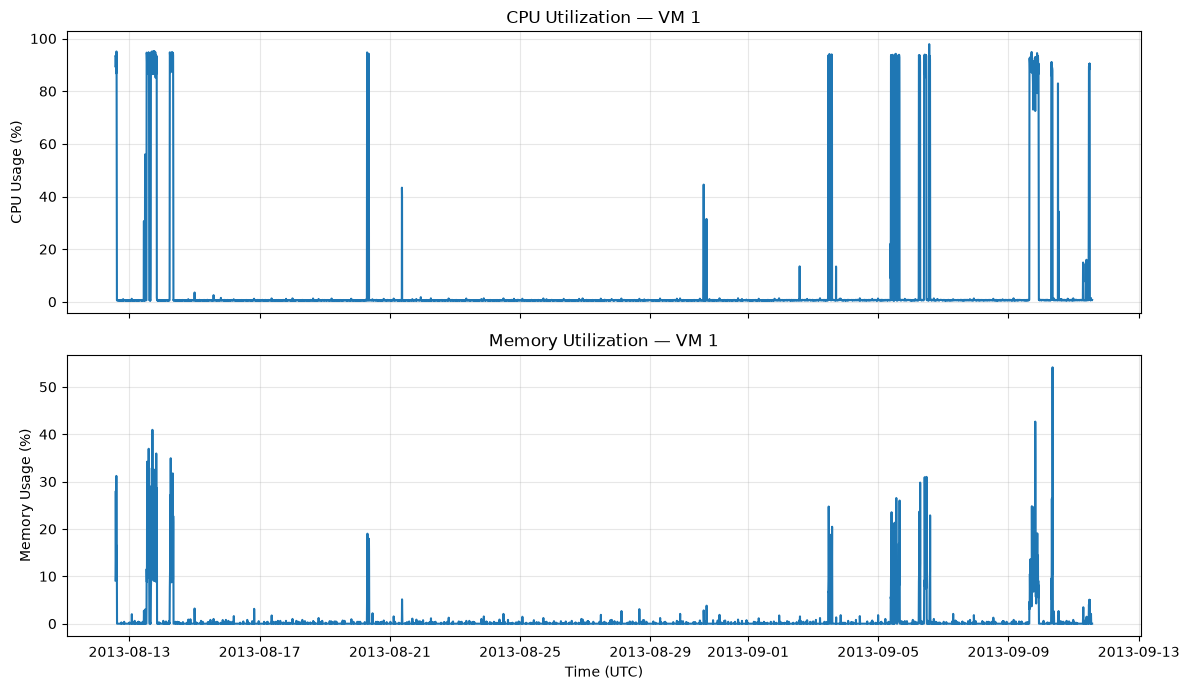

In [22]:
#visualize CPU utilization against time

import matplotlib.pyplot as plt
import pandas as pd

# Create readable timestamps from Unix seconds
time = pd.to_datetime(
    df["Timestamp [ms]"],
    unit="s",
    utc=True
)

# Calculate memory utilization percentage
memory_pct = (
    df["Memory usage [KB]"] /
    df["Memory capacity provisioned [KB]"]
) * 100

# Plot CPU and memory on separate charts
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(time, df["CPU usage [%]"])
axes[0].set_title("CPU Utilization — VM 1")
axes[0].set_ylabel("CPU Usage (%)")
axes[0].grid(alpha=0.3)

axes[1].plot(time, memory_pct)
axes[1].set_title("Memory Utilization — VM 1")
axes[1].set_ylabel("Memory Usage (%)")
axes[1].set_xlabel("Time (UTC)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


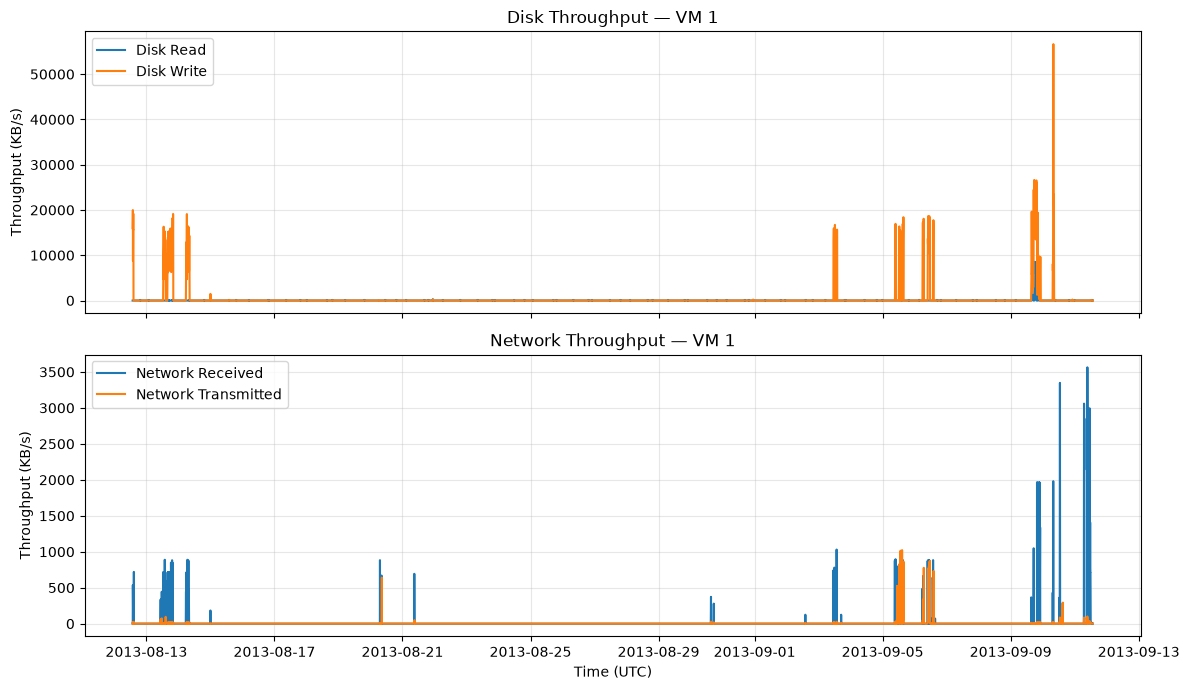

In [31]:

# Disk and network workload exploration — VM 1

disk_read = df["Disk read throughput [KB/s]"]
disk_write = df["Disk write throughput [KB/s]"]

network_received = df["Network received throughput [KB/s]"]
network_transmitted = df["Network transmitted throughput [KB/s]"]

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

# Disk activity
axes[0].plot(time, disk_read, label="Disk Read")
axes[0].plot(time, disk_write, label="Disk Write")
axes[0].set_title("Disk Throughput — VM 1")
axes[0].set_ylabel("Throughput (KB/s)")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Network activity
axes[1].plot(time, network_received, label="Network Received")
axes[1].plot(time, network_transmitted, label="Network Transmitted")
axes[1].set_title("Network Throughput — VM 1")
axes[1].set_ylabel("Throughput (KB/s)")
axes[1].set_xlabel("Time (UTC)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
fig.savefig(
    "E:/Cloud_cost_capstone/figures/vm1_cpu_memory.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


In [27]:

import numpy as np
import pandas as pd

# Use the 1,250 CSV files already discovered
all_files = sorted(csv_files)

# Select 100 VM files using a fixed random seed
rng = np.random.default_rng(seed=42)

selected_indices = rng.choice(
    len(all_files),
    size=100,
    replace=False
)

selected_files = sorted(
    [all_files[i] for i in selected_indices],
    key=lambda p: int(p.stem)
)

print("Total available VM files:", len(all_files))
print("Selected VM files:", len(selected_files))
print("\nFirst 10 selected VMs:")

for file in selected_files[:10]:
    print(file.name)


Total available VM files: 1250
Selected VM files: 100

First 10 selected VMs:
3.csv
17.csv
23.csv
28.csv
36.csv
40.csv
55.csv
59.csv
60.csv
63.csv


In [28]:

from pathlib import Path

# Your existing project folder
project_dir = Path("E:/Cloud_cost_capstone")

# Save the exact selected VM filenames
selection_df = pd.DataFrame({
    "VM_ID": [file.stem for file in selected_files],
    "Filename": [file.name for file in selected_files]
})

output_file = project_dir / "reports" / "selected_vm_ids.csv"

output_file.parent.mkdir(parents=True, exist_ok=True)
selection_df.to_csv(output_file, index=False)

print("Selection saved to:", output_file)
display(selection_df.head(10))


Selection saved to: E:\Cloud_cost_capstone\reports\selected_vm_ids.csv


,VM_ID,Filename
0,3,3.csv
1,17,17.csv
2,23,23.csv
3,28,28.csv
4,36,36.csv
5,40,40.csv
6,55,55.csv
7,59,59.csv
8,60,60.csv
9,63,63.csv


In [29]:

print("Selected files:", len(selected_files))
print("Unique VM IDs:", len(set(file.stem for file in selected_files)))
print("All files exist:", all(file.exists() for file in selected_files))


Selected files: 100
Unique VM IDs: 100
All files exist: True
